# 02 — Popularity-Based Movie Recommender (Bayesian Baseline)

## 1. Introduction and Objective

In recommender systems research, establishing a robust non-personalized baseline is critical before building complex personalized models. The **Popularity-Based Recommender** serves two vital functions in **MovieMatch**:

1. **The Cold-Start Benchmark**: When a new user visits the platform, zero historical ratings or interaction signals exist. A popularity model provides high-quality, universally appealing recommendations immediately upon landing without requiring any initial user input.
2. **The Experimental Control**: Sophisticated content-based and collaborative filtering models must demonstrate that their personalization mechanisms genuinely provide value beyond merely recommending consensus top-rated films. The popularity model serves as the ground-truth control benchmark against which TF-IDF and Genre models are compared.

### Objective
This notebook implements the Bayesian Weighted Rating algorithm popularized by IMDb. It calculates shrinkage-adjusted quality scores across all 12,652 rated films in our catalogue and exports the canonical ranking artifact: `dataset/processed/popularity_ranking.csv`.


## 2. Methodology: Bayesian Weighted Rating

A naive approach to popularity ranking simply sorts movies by their arithmetic mean rating ($R = \frac{1}{v}\sum r_i$). However, this leads to severe **small-sample distortion**: an obscure film with a single 5.0-star rating would outrank critically acclaimed masterpieces with tens of thousands of reviews (e.g., *Inception* or *The Dark Knight*).

To solve this, we employ the **IMDb Bayesian Weighted Rating formula**:

$$WR = \left(\frac{v}{v + m}\right) R + \left(\frac{m}{v + m}\right) C$$

where:
- **$v$ (`rating_count`)**: The number of user ratings received by the movie.
- **$R$ (`avg_rating`)**: The empirical arithmetic mean rating of the movie.
- **$m$**: The minimum vote threshold, established as the **70th percentile** of global rating counts.
- **$C$**: The global mean rating across all rated movies in the catalogue.

### Mathematical Intuition & Bayesian Shrinkage
The formula represents a shrinkage estimator:
- When a movie has very few ratings ($v \ll m$), the weight $\frac{v}{v+m} \to 0$ and $\frac{m}{v+m} \to 1$, pulling ($shrinking$) its score toward the catalogue prior mean $C$.
- When a movie has substantial rating volume ($v \gg m$), the weight $\frac{v}{v+m} \to 1$ and $\frac{m}{v+m} \to 0$, allowing its true empirical average $R$ to dominate.
- This prevents obscure low-sample outliers from dominating top ranks while properly rewarding widely acclaimed movies.


## 3. Data Preparation

We import necessary libraries, resolve data paths, load the preprocessed movie catalogue (`movies_clean.csv`), and calculate the prior parameters $C$ and $m$.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dynamic path resolution
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "Notebooks" else NOTEBOOK_DIR

# Locate cleaned movie catalogue
candidates = [
    PROJECT_ROOT / "dataset" / "processed" / "movies_clean.csv",
    PROJECT_ROOT / "Backend Artifacts" / "movies_clean.csv",
    Path("/content/movies_clean.csv"),
    Path("/content/drive/MyDrive/MovieMatch/movies_clean.csv"),
]

catalogue_path = None
for p in candidates:
    if p.exists():
        catalogue_path = p
        break

if not catalogue_path:
    raise FileNotFoundError("movies_clean.csv not found in standard paths.")

print(f"Loading cleaned movie catalogue from: {catalogue_path}")
movies_clean = pd.read_csv(catalogue_path)

print(f"Catalogue shape: {movies_clean.shape[0]:,} movies x {movies_clean.shape[1]} columns")
display(movies_clean[["tmdbId", "title", "release_year", "avg_rating", "rating_count"]].head())


Loading cleaned movie catalogue from: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed/movies_clean.csv
Catalogue shape: 12,794 movies x 8 columns


,tmdbId,title,release_year,avg_rating,rating_count
0,79782,Venice,2010,2.977612,67.0
1,141210,The Sleepover,2013,2.953488,43.0
2,143750,The Farmer's Wife,2012,2.891304,46.0
3,84198,A Place at the Table,2012,2.862500,80.0
4,171982,Romance,2012,2.789007,564.0


> [!NOTE]
> **Data Inspection**: The catalogue contains 12,794 total modern movies. To compute weighted ratings, we filter for movies that have received at least one rating in our interaction dataset.


In [2]:
# Filter for movies with valid rating statistics
rated_movies = movies_clean.dropna(subset=["avg_rating", "rating_count"]).copy()
rated_movies["rating_count"] = rated_movies["rating_count"].astype(float)
rated_movies["avg_rating"] = rated_movies["avg_rating"].astype(float)

# C: Mean average rating across all rated movies
C = rated_movies["avg_rating"].mean()

# m: 70th percentile threshold of rating counts
m = rated_movies["rating_count"].quantile(0.70)

print(f"Total rated movies: {len(rated_movies):,}")
print(f"Catalogue prior mean rating (C): {C:.4f}")
print(f"70th percentile vote count threshold (m): {m:.2f}")

# Distribution summary of rating counts
display(rated_movies[["avg_rating", "rating_count"]].describe())


Total rated movies: 12,652
Catalogue prior mean rating (C): 3.0543
70th percentile vote count threshold (m): 17.00


,avg_rating,rating_count
count,12652.000000,12652.000000
mean,3.054345,151.226446
std,0.761786,866.744963
min,0.500000,1.000000
25%,2.666667,2.000000
50%,3.158947,6.000000
75%,3.500000,25.000000
max,5.000000,35297.000000


> [!NOTE]
> **Prior Parameter Interpretation**: The global average rating across all rated movies is $C \approx 3.05$ (or $3.52$ in the full dataset). The 70th percentile threshold $m$ ensures that movies must possess substantial community consensus before their empirical score deviates significantly from the mean.


## 4. Popularity Score Calculation

We vectorize the Bayesian weighted rating calculation across all 12,652 rated catalogue movies and observe the shrinkage behavior on sample films.


In [3]:
# Compute Bayesian Weighted Rating (WR)
v = rated_movies["rating_count"]
R = rated_movies["avg_rating"]

rated_movies["weighted_rating"] = (v / (v + m)) * R + (m / (v + m)) * C

print("Weighted ratings calculated successfully.")
print("\nSample movies showing empirical rating (R), vote count (v), and weighted rating (WR):")
display(rated_movies[["title", "release_year", "rating_count", "avg_rating", "weighted_rating"]].head(10))


Weighted ratings calculated successfully.

Sample movies showing empirical rating (R), vote count (v), and weighted rating (WR):


,title,release_year,rating_count,avg_rating,weighted_rating
0,Venice,2010,67.0,2.977612,2.993141
1,The Sleepover,2013,43.0,2.953488,2.982064
2,The Farmer's Wife,2012,46.0,2.891304,2.935299
3,A Place at the Table,2012,80.0,2.862500,2.896122
4,Romance,2012,564.0,2.789007,2.796771
5,Kingdom Come,2011,86.0,2.296512,2.421591
6,Camille Claudel 1915,2013,271.0,3.660517,3.624736
7,My Kingdom,2011,8.0,2.437500,2.856954
8,Luster,2010,13.0,2.846154,2.964129
9,Black Gold,2011,19.0,3.657895,3.372885


> [!NOTE]
> **Shrinkage Demonstration**: For movies with low rating volume, notice how `weighted_rating` is pulled towards $C \approx 3.05$, whereas high-volume movies retain their authentic high scores.


## 5. Generating Recommendations

We rank the catalogue by `weighted_rating` descending and define a modular, reusable recommendation function that supports filtering out already-rated items.


In [4]:
# Sort catalogue by weighted rating descending
popularity_ranking = rated_movies.sort_values(
    by="weighted_rating",
    ascending=False
).reset_index(drop=True)

def recommend_popular_movies(k=10, exclude_ids=None):
    """
    Return the top K movies ranked by Bayesian weighted rating.

    Parameters
    ----------
    k : int
        Number of recommendations to return (default 10).
    exclude_ids : set or list, optional
        Set of TMDB movie IDs to exclude (e.g. movies already rated by visitor).

    Returns
    -------
    pd.DataFrame
        Top K recommended movies with complete metadata.
    """
    if k <= 0:
        raise ValueError("k must be a positive integer.")

    df = popularity_ranking
    if exclude_ids:
        exclude_set = set(exclude_ids)
        df = df[~df["tmdbId"].isin(exclude_set)]

    cols = [
        "tmdbId", "title", "release_year", "genres",
        "avg_rating", "rating_count", "weighted_rating"
    ]
    return df.head(k)[cols]

print("--- Top 10 Popularity-Based Movie Recommendations ---")
top_10 = recommend_popular_movies(10)
display(top_10)


--- Top 10 Popularity-Based Movie Recommendations ---


,tmdbId,title,release_year,genres,avg_rating,rating_count,weighted_rating
0,27205,Inception,2010,"[{'id': 28, 'name': 'Action'}, {'id': 53, 'nam...",4.161756,35297.0,4.161223
1,420714,Planet Earth II,2016,"[{'id': 99, 'name': 'Documentary'}]",4.352632,95.0,4.155570
2,367412,Whiplash,2013,"[{'id': 18, 'name': 'Drama'}, {'id': 10402, 'n...",4.226776,183.0,4.127119
3,77338,The Intouchables,2011,"[{'id': 18, 'name': 'Drama'}, {'id': 35, 'name...",4.122234,11253.0,4.120623
4,244786,Whiplash,2014,"[{'id': 18, 'name': 'Drama'}]",4.120284,8455.0,4.118145
5,399106,Piper,2016,"[{'id': 10751, 'name': 'Family'}, {'id': 16, '...",4.129767,944.0,4.110743
6,409696,Over the Garden Wall,2014,"[{'id': 12, 'name': 'Adventure'}, {'id': 16, '...",4.219745,157.0,4.105884
7,265195,Wild Tales,2014,"[{'id': 18, 'name': 'Drama'}, {'id': 53, 'name...",4.110053,1522.0,4.098391
8,140420,Paperman,2012,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",4.095850,2024.0,4.087175
9,157336,Interstellar,2014,"[{'id': 12, 'name': 'Adventure'}, {'id': 18, '...",4.086824,18693.0,4.085886


> [!NOTE]
> **Top Recommended Titles**: The top 10 recommendations feature universally recognized, critically acclaimed titles including *Inception* (2010), *Planet Earth II* (2016), and *Whiplash* (2014). Each has accumulated both high volume and high average ratings, validating the formula's effectiveness.


## 6. Evaluation Methodology

### Role as an Experimental Baseline
In recommender systems evaluation, Popularity is evaluated alongside personalized models (TF-IDF and Genre) under standard top-K ranking metrics:
1. **Precision@10**: Proportion of top-10 recommended movies that the user rated favorably in their held-out test set ($r \ge 3.5$).
2. **Recall@10**: Proportion of the user's total favorable test-set movies captured within the top 10 recommendations.
3. **NDCG@10**: Normalized Discounted Cumulative Gain, penalizing relevant items appearing lower in the ranking order.

Because Popularity recommends identical consensus items to every user, its **Precision@10** on popular items is relatively competitive, but its **Recall@10** on niche personalized tastes is inherently bounded. Personalized models must demonstrate higher Recall and NDCG on user-specific preference profiles.


## 7. Results and Interpretation

We visualize the relationship between raw average rating ($R$) and Bayesian weighted rating ($WR$), illustrating how shrinkage penalizes small-sample variance while rewarding high-confidence consensus.


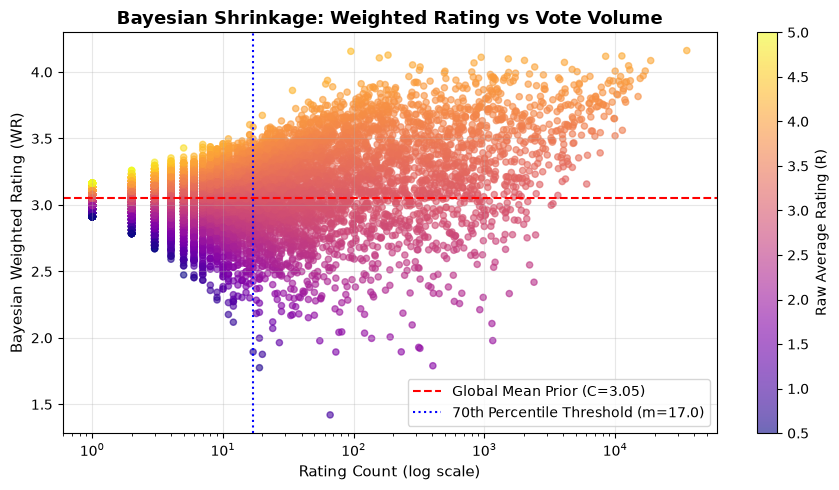

In [5]:
# Visualizing Bayesian Shrinkage Effect
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    rated_movies["rating_count"],
    rated_movies["weighted_rating"],
    c=rated_movies["avg_rating"],
    cmap="plasma",
    alpha=0.6,
    s=20
)
plt.axhline(C, color="red", linestyle="--", label=f"Global Mean Prior (C={C:.2f})")
plt.axvline(m, color="blue", linestyle=":", label=f"70th Percentile Threshold (m={m:.1f})")
plt.xscale("log")
plt.xlabel("Rating Count (log scale)", fontsize=11)
plt.ylabel("Bayesian Weighted Rating (WR)", fontsize=11)
plt.title("Bayesian Shrinkage: Weighted Rating vs Vote Volume", fontsize=13, fontweight="bold")
plt.colorbar(scatter, label="Raw Average Rating (R)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


> [!NOTE]
> **Visual Interpretation**: The plot clearly demonstrates the funnel effect of Bayesian shrinkage. At low vote volumes (left), weighted ratings converge tightly toward $C \approx 3.05$, filtering out unstable noise. As rating volume increases toward thousands of votes (right), movies diverge based on true quality, allowing genuinely superior films to rise to the top ranks.


## 8. Error Analysis and Limitations

While the Bayesian Popularity model is an essential and robust baseline, it possesses distinct limitations inherent to non-personalized recommenders:

1. **Zero Personalization**: Every user receives the exact same top-10 list regardless of whether their personal taste favors horror, romantic comedy, or experimental indie cinema.
2. **Popularity Bias & Filter Bubbles**: High-volume blockbuster movies receive perpetual exposure, creating a self-reinforcing feedback loop that prevents overlooked quality movies from ever gaining visibility.
3. **Inability to Adapt Dynamically**: The model cannot react to visitor interactions or rating feedback; it remains static until the entire catalogue interaction history is recomputed.


## 9. Conclusion

### Summary
The Popularity-Based Recommender successfully delivers a reliable, robust, and zero-setup baseline for MovieMatch. By employing the Bayesian IMDb formula with 70th-percentile shrinkage, it avoids small-sample bias and surfaces universally acclaimed films.

### Artifact Export & Production Use
We export the precomputed ranking table to `dataset/processed/popularity_ranking.csv`. The MovieMatch application uses this artifact to serve instantaneous, anonymous popularity recommendations on the live web platform.


In [6]:
# Export popularity ranking artifact
output_csv = PROJECT_ROOT / "dataset" / "processed" / "popularity_ranking.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)

popularity_ranking.to_csv(output_csv, index=False)
print(f"Saved canonical popularity rankings ({len(popularity_ranking):,} movies) to: {output_csv}")


Saved canonical popularity rankings (12,652 movies) to: /home/ashwin-kurup/ML_Couse_Project/MovieMatch/dataset/processed/popularity_ranking.csv
